In [ ]:
#1 Requirement 1: Prepare the XOR dataset

# Import NumPy for numerical calculations
import numpy as np

# Import Matplotlib for plotting the loss curve later
import matplotlib.pyplot as plt

# XOR input data (4 samples, 2 input features)
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

# Expected output labels
y = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)

# Display the dataset
print("Input data (X):")
print(X)

print("\nTarget labels (y):")
print(y)

# Display the shapes of the arrays
print("\nInput shape:", X.shape)
print("Target shape:", y.shape)


Input data (X):
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]

Target labels (y):
[[0.]
 [1.]
 [1.]
 [0.]]

Input shape: (4, 2)
Target shape: (4, 1)


In [ ]:
#2 Requirement 2: Define activation and loss functions

# ReLU activation function
def relu(x):
    return np.maximum(0, x)


# Sigmoid activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


# Softmax activation function
def softmax(x):
    exp_values = np.exp(x - np.max(x))
    return exp_values / np.sum(exp_values)


# Mean Squared Error loss function
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


# Cross-Entropy loss function
def cross_entropy(y_true, y_pred):
    epsilon = 1e-12
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )


In [ ]:
#3 Requirement 2: Test activation and loss functions

# Test ReLU
print("ReLU:", relu(np.array([-2, 0, 2])))

# Test Sigmoid
print("Sigmoid:", sigmoid(np.array([0, 1, -1])))

# Test Softmax using the values given in the PDF
print("Softmax:", softmax(np.array([2.0, 1.0, 0.1])))

# Test Mean Squared Error
y_true = np.array([1, 0, 1])
y_pred = np.array([0.8, 0.2, 0.9])
print("MSE:", mse(y_true, y_pred))

# Test Cross-Entropy
print("Cross-Entropy:", cross_entropy(y_true, y_pred))


ReLU: [0 0 2]
Sigmoid: [0.5        0.73105858 0.26894142]
Softmax: [0.65900114 0.24243297 0.09856589]
MSE: 0.029999999999999995
Cross-Entropy: 0.18388253942874858


In [14]:
#4 Requirement 1: Initialize the 2-4-1 neural network

# Set random seed for reproducible results
np.random.seed(0)

# Input layer (2) -> Hidden layer (4)
W1 = np.random.randn(2, 4) * 0.5
b1 = np.ones((1, 4)) * 0.1

# Hidden layer (4) -> Output layer (1)
W2 = np.random.randn(4, 1) * 0.5
b2 = np.zeros((1, 1))

# Display weight and bias shapes
print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)


W1 shape: (2, 4)
b1 shape: (1, 4)
W2 shape: (4, 1)
b2 shape: (1, 1)


In [ ]:
#5 Requirement 1: Forward propagation

# Calculate hidden layer input
hidden_input = np.dot(X, W1) + b1

# Apply ReLU activation to hidden layer
hidden_output = relu(hidden_input)

# Calculate output layer input
output_input = np.dot(hidden_output, W2) + b2

# Apply Sigmoid activation to get predictions
predictions = sigmoid(output_input)

# Display initial predictions
print("Initial predictions:")
print(predictions)


Initial predictions:
[[0.5238032 ]
 [0.50143698]
 [0.71926185]
 [0.69215004]]


In [ ]:
#6 Requirement 1: Train the XOR neural network using backpropagation

# Set training parameters
learning_rate = 0.5
epochs = 5000

# Store loss values for plotting
loss_history = []

# Training loop
for epoch in range(epochs):

    # Forward propagation
    hidden_input = np.dot(X, W1) + b1
    hidden_output = relu(hidden_input)

    output_input = np.dot(hidden_output, W2) + b2
    predictions = sigmoid(output_input)

    # Calculate binary cross-entropy loss
    loss = cross_entropy(y, predictions)
    loss_history.append(loss)

    # Backpropagation: calculate output layer gradients
    output_error = (predictions - y) / len(X)
    dW2 = np.dot(hidden_output.T, output_error)
    db2 = np.sum(output_error, axis=0, keepdims=True)

    # Backpropagation: calculate hidden layer gradients
    hidden_error = np.dot(output_error, W2.T)
    hidden_error *= (hidden_input > 0)

    dW1 = np.dot(X.T, hidden_error)
    db1 = np.sum(hidden_error, axis=0, keepdims=True)

    # Update weights and biases using gradient descent
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

# Display training results
print("Training completed!")
print("Epochs:", epochs)
print("Learning rate:", learning_rate)
print("Final loss:", loss_history[-1])


Training completed!
Epochs: 5000
Learning rate: 0.5
Final loss: 0.00018933392139922528


In [ ]:
#7 Requirement 1: Check the network predictions after training

# Perform forward propagation using the trained weights
hidden_input = np.dot(X, W1) + b1
hidden_output = relu(hidden_input)

output_input = np.dot(hidden_output, W2) + b2
final_predictions = sigmoid(output_input)

# Display actual and predicted outputs
print("Actual XOR outputs:")
print(y.flatten())

print("\nPredicted probabilities:")
print(final_predictions.flatten())

print("\nPredicted classes:")
print((final_predictions >= 0.5).astype(int).flatten())


Actual XOR outputs:
[0. 1. 1. 0.]

Predicted probabilities:
[2.89851681e-04 9.99795799e-01 9.99871205e-01 1.34158191e-04]

Predicted classes:
[0 1 1 0]


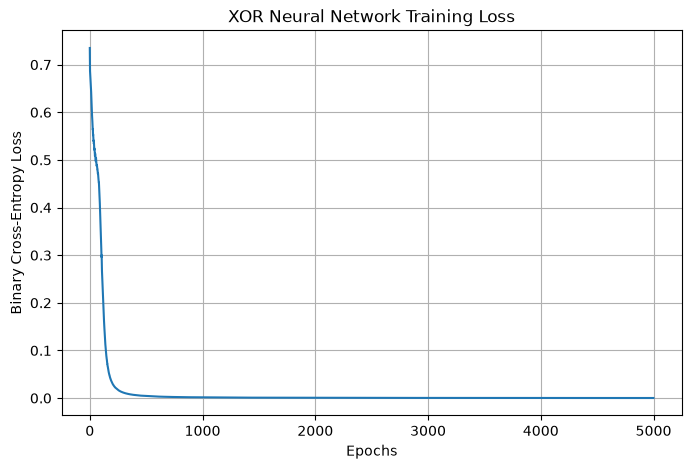

In [ ]:
#8 Requirement 1: Plot the training loss curve

plt.figure(figsize=(8, 5))

# Plot loss against training epochs
plt.plot(loss_history)

# Add chart labels and title
plt.title("XOR Neural Network Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")

plt.grid(True)
plt.show()


In [ ]:
#9 Requirement 3: Calculate gradients manually

# Given values from the assessment PDF
w = 1
x = 2
b = 0
t = 10

# Calculate the prediction
prediction = w * x + b

# Calculate the loss
loss = (prediction - t) ** 2

# Calculate gradients manually
dw = 2 * (prediction - t) * x
db = 2 * (prediction - t)

# Display results
print("Prediction:", prediction)
print("Loss:", loss)
print("Manual gradient dw:", dw)
print("Manual gradient db:", db)


Prediction: 2
Loss: 64
Manual gradient dw: -32
Manual gradient db: -16


In [27]:
#10 Requirement 3: Verify manual gradients using PyTorch autograd

import torch


# Create tensors with gradient tracking enabled
w_torch = torch.tensor(1.0, requires_grad=True)
b_torch = torch.tensor(0.0, requires_grad=True)

# Given values
x_torch = torch.tensor(2.0)
t_torch = torch.tensor(10.0)

# Calculate prediction and loss
prediction_torch = w_torch * x_torch + b_torch
loss_torch = (prediction_torch - t_torch) ** 2

# Calculate gradients automatically
loss_torch.backward()

# Display PyTorch gradients
print("PyTorch gradient dw:", w_torch.grad.item())
print("PyTorch gradient db:", b_torch.grad.item())


PyTorch gradient dw: -32.0
PyTorch gradient db: -16.0


In [28]:
#11 Requirement 4: Demonstrate slow learning with learning rate 0.01

# Reset the neural network weights and biases
np.random.seed(0)

W1_slow = np.random.randn(2, 4) * 0.5
b1_slow = np.ones((1, 4)) * 0.1

W2_slow = np.random.randn(4, 1) * 0.5
b2_slow = np.zeros((1, 1))

# Set a smaller learning rate
learning_rate_slow = 0.01
epochs = 5000

slow_loss_history = []

# Train the network
for epoch in range(epochs):

    # Forward propagation
    hidden_input = np.dot(X, W1_slow) + b1_slow
    hidden_output = relu(hidden_input)

    output_input = np.dot(hidden_output, W2_slow) + b2_slow
    predictions_slow = sigmoid(output_input)

    # Calculate loss
    loss = cross_entropy(y, predictions_slow)
    slow_loss_history.append(loss)

    # Backpropagation
    output_error = (predictions_slow - y) / len(X)

    dW2 = np.dot(hidden_output.T, output_error)
    db2 = np.sum(output_error, axis=0, keepdims=True)

    hidden_error = np.dot(output_error, W2_slow.T)
    hidden_error *= (hidden_input > 0)

    dW1 = np.dot(X.T, hidden_error)
    db1 = np.sum(hidden_error, axis=0, keepdims=True)

    # Update weights and biases
    W2_slow -= learning_rate_slow * dW2
    b2_slow -= learning_rate_slow * db2

    W1_slow -= learning_rate_slow * dW1
    b1_slow -= learning_rate_slow * db1

# Display final loss
print("Learning rate:", learning_rate_slow)
print("Final loss:", slow_loss_history[-1])


Learning rate: 0.01
Final loss: 0.3033048010436958


In [ ]:
#12 Requirement 4: Demonstrate unstable training with learning rate 5

# Reset the network with a different random seed
np.random.seed(183)

# Initialize weights and biases
W1_fast = np.random.randn(2, 4) * 0.5
b1_fast = np.ones((1, 4)) * 0.1

W2_fast = np.random.randn(4, 1) * 0.5
b2_fast = np.zeros((1, 1))

# Set learning rate and epochs
learning_rate_fast = 5
epochs = 5000

fast_loss_history = []

# Training loop
for epoch in range(epochs):

    # Forward propagation
    hidden_input = np.dot(X, W1_fast) + b1_fast
    hidden_output = relu(hidden_input)

    output_input = np.dot(hidden_output, W2_fast) + b2_fast
    predictions_fast = sigmoid(output_input)

    # Calculate loss
    loss = cross_entropy(y, predictions_fast)
    fast_loss_history.append(loss)

    # Backpropagation
    output_error = (predictions_fast - y) / len(X)

    dW2 = np.dot(hidden_output.T, output_error)
    db2 = np.sum(output_error, axis=0, keepdims=True)

    hidden_error = np.dot(output_error, W2_fast.T)
    hidden_error *= (hidden_input > 0)

    dW1 = np.dot(X.T, hidden_error)
    db1 = np.sum(hidden_error, axis=0, keepdims=True)

    # Update weights and biases
    W2_fast -= learning_rate_fast * dW2
    b2_fast -= learning_rate_fast * db2
    W1_fast -= learning_rate_fast * dW1
    b1_fast -= learning_rate_fast * db1

# Display results
print("Learning rate:", learning_rate_fast)
print("Initial loss:", fast_loss_history[0])
print("Maximum loss:", max(fast_loss_history))
print("Final loss:", fast_loss_history[-1])


Learning rate: 5
Initial loss: 0.7250148394130141
Maximum loss: 2.914268293619793
Final loss: 0.6931471805599453


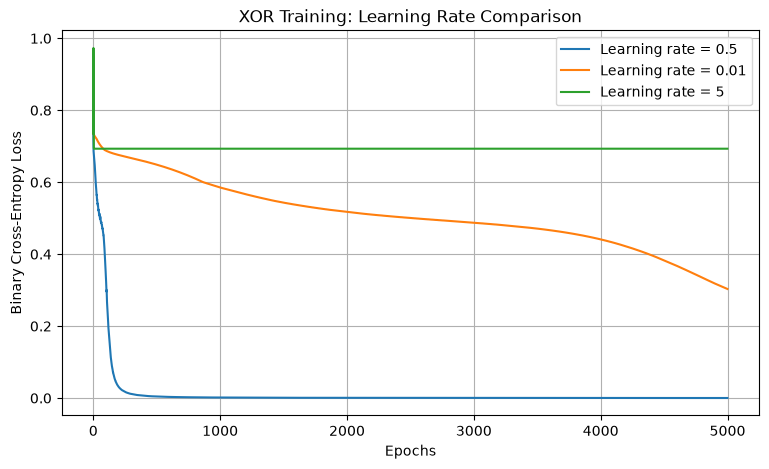

In [30]:
#13 Requirement 4: Compare loss curves for different learning rates

plt.figure(figsize=(9, 5))

# Plot the normal learning rate
plt.plot(loss_history, label="Learning rate = 0.5")

# Plot the slow learning rate
plt.plot(slow_loss_history, label="Learning rate = 0.01")

# Plot the high learning rate
plt.plot(fast_loss_history, label="Learning rate = 5")

# Add chart details
plt.title("XOR Training: Learning Rate Comparison")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)

plt.show()


# 13. Requirement 5: Regularization Techniques

### 1. Dropout
- Dropout randomly disables some neurons during training to prevent overfitting.
- It helps the neural network learn better features instead of depending on specific neurons.

### 2. Batch Normalization
- Batch Normalization normalizes the inputs to a layer during training.
- It helps make training more stable and faster.

### 3. Early Stopping
- Early Stopping stops training when the validation loss stops improving.
- It helps prevent overfitting and saves training time.

In [ ]:
# task2

#1 - Requirement 1: Import libraries and load dataset

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load breast cancer dataset
data = load_breast_cancer()

X = data.data
y = data.target

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Class labels:", np.unique(y))



Features shape: (569, 30)
Target shape: (569,)
Class labels: [0 1]


In [34]:
#2 Task 2 - Requirement 1: Scale features and split dataset

# Split dataset into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training targets:", y_train.shape)
print("Validation targets:", y_val.shape)


Training features: (455, 30)
Validation features: (114, 30)
Training targets: (455,)
Validation targets: (114,)


In [35]:
#3 Task 2 - Requirement 1: Create CsvDataset class

class CsvDataset(Dataset):

    def __init__(self, features, targets):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):
        return self.features[index], self.targets[index]


# Create training and validation datasets
train_dataset = CsvDataset(X_train, y_train)
val_dataset = CsvDataset(X_val, y_val)

print("Training dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))

# Check one sample
sample_features, sample_target = train_dataset[0]

print("Sample features shape:", sample_features.shape)
print("Sample target:", sample_target)


Training dataset size: 455
Validation dataset size: 114
Sample features shape: torch.Size([30])
Sample target: tensor(1.)


In [36]:
#4 Task 2 - Requirement 2: Create DataLoaders

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training batches: 15
Validation batches: 4


In [43]:
#5 Task 2 - Requirement 3: Build MLP model

class MLP(nn.Module):

    def __init__(self):
        super(MLP, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(30, 47),
            nn.BatchNorm1d(47),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(47, 48),
            nn.BatchNorm1d(48),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(48, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)


# Initialize model
model = MLP()

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total parameters:", total_params)


Total parameters: 4000


In [39]:
#6 Task 2 - Requirement 3: Verify model output

# Get one batch from training DataLoader
sample_features, sample_targets = next(iter(train_loader))

# Pass sample features through the model
predictions = model(sample_features)

print("Input shape:", sample_features.shape)
print("Output shape:", predictions.shape)


Input shape: torch.Size([32, 30])
Output shape: torch.Size([32, 1])


In [44]:
#7 Task 2 - Requirement 4: Define loss function and Adam optimizer

criterion = nn.BCELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)


Loss function: BCELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [45]:
#8 Task 2 - Requirement 4: Training loop with early stopping

epochs = 40
patience = 5

train_losses = []
val_accuracies = []

best_val_accuracy = 0
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

for epoch in range(epochs):

    # Training
    model.train()
    running_loss = 0.0

    for features, targets in train_loader:

        targets = targets.unsqueeze(1)

        optimizer.zero_grad()

        outputs = model(features)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():

        for features, targets in val_loader:

            targets = targets.unsqueeze(1)
            outputs = model(features)

            predictions = (outputs >= 0.5).float()

            correct += (predictions == targets).sum().item()
            total += targets.size(0)

    val_accuracy = correct / total
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {train_loss:.4f}, "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

    # Early stopping
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1
        best_model_state = {
            key: value.clone()
            for key, value in model.state_dict().items()
        }
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore best model
model.load_state_dict(best_model_state)

print("\nBest validation accuracy:", best_val_accuracy)
print("Best epoch:", best_epoch)
print("Total epochs trained:", len(train_losses))


Epoch [1/40], Loss: 0.5480, Validation Accuracy: 0.9298
Epoch [2/40], Loss: 0.3686, Validation Accuracy: 0.9561
Epoch [3/40], Loss: 0.2999, Validation Accuracy: 0.9561
Epoch [4/40], Loss: 0.2631, Validation Accuracy: 0.9474
Epoch [5/40], Loss: 0.2118, Validation Accuracy: 0.9561
Epoch [6/40], Loss: 0.1795, Validation Accuracy: 0.9649
Epoch [7/40], Loss: 0.1655, Validation Accuracy: 0.9649
Epoch [8/40], Loss: 0.1510, Validation Accuracy: 0.9649
Epoch [9/40], Loss: 0.1574, Validation Accuracy: 0.9649
Epoch [10/40], Loss: 0.1457, Validation Accuracy: 0.9649
Epoch [11/40], Loss: 0.1149, Validation Accuracy: 0.9649
Early stopping triggered.

Best validation accuracy: 0.9649122807017544
Best epoch: 6
Total epochs trained: 11


In [46]:
#9 Task 2 - Requirement 5: Save model state_dict

torch.save(model.state_dict(), "breast_cancer_model.pth")

print("Model saved successfully!")


Model saved successfully!


In [47]:

#10 Task 2 - Requirement 5: Load saved model into a new model

# Create a new model
loaded_model = MLP()

# Load saved weights
loaded_model.load_state_dict(
    torch.load("breast_cancer_model.pth", weights_only=True)
)

# Set model to evaluation mode
loaded_model.eval()

print("Model loaded successfully!")
print("Model is in evaluation mode:", not loaded_model.training)


Model loaded successfully!
Model is in evaluation mode: True


In [48]:

#11 Task 2 - Requirement 5: Compare original and reloaded model accuracy

def calculate_accuracy(model_to_test):

    model_to_test.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for features, targets in val_loader:

            targets = targets.unsqueeze(1)

            outputs = model_to_test(features)
            predictions = (outputs >= 0.5).float()

            correct += (predictions == targets).sum().item()
            total += targets.size(0)

    return correct / total


original_accuracy = calculate_accuracy(model)
reloaded_accuracy = calculate_accuracy(loaded_model)

print("Original model accuracy:", original_accuracy)
print("Reloaded model accuracy:", reloaded_accuracy)
print("Accuracy identical:", original_accuracy == reloaded_accuracy)


Original model accuracy: 0.9649122807017544
Reloaded model accuracy: 0.9649122807017544
Accuracy identical: True


In [49]:

#12 Task 2 - Requirement 5: Compare with Logistic Regression

# Create and train Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train, y_train)

# Predict validation data
logistic_predictions = logistic_model.predict(X_val)

# Calculate accuracy
logistic_accuracy = accuracy_score(y_val, logistic_predictions)

print("PyTorch MLP accuracy:", original_accuracy)
print("Logistic Regression accuracy:", logistic_accuracy)


PyTorch MLP accuracy: 0.9649122807017544
Logistic Regression accuracy: 0.9824561403508771


In [18]:
# task3

#1 Task 3 - Requirement 1: Import libraries

import numpy as np
import pandas as pd
import re

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print("Libraries imported successfully!")


Libraries imported successfully!


In [19]:

#2 Task 3 - Requirement 1: Create 400 unique labelled texts

from itertools import product

positive_starters = [
    "I had a",
    "I received a",
    "I experienced a",
    "Overall it was a",
    "The customer had a"
]

positive_words = [
    "wonderful",
    "excellent",
    "fantastic",
    "pleasant",
    "satisfying"
]

positive_topics = [
    "product experience",
    "customer service",
    "shopping experience",
    "delivery service",
    "support experience",
    "purchase experience",
    "application experience",
    "business experience"
]

negative_starters = [
    "I had a",
    "I received a",
    "I experienced a",
    "Overall it was a",
    "The customer had a"
]

negative_words = [
    "terrible",
    "awful",
    "disappointing",
    "frustrating",
    "unpleasant"
]

negative_topics = [
    "product experience",
    "customer service",
    "shopping experience",
    "delivery service",
    "support experience",
    "purchase experience",
    "application experience",
    "business experience"
]

# Generate unique sentences
positive_texts = [
    f"{starter} {word} {topic}."
    for starter, word, topic in product(
        positive_starters, positive_words, positive_topics
    )
]

negative_texts = [
    f"{starter} {word} {topic}."
    for starter, word, topic in product(
        negative_starters, negative_words, negative_topics
    )
]

texts = positive_texts + negative_texts
labels = [1] * 200 + [0] * 200

df = pd.DataFrame({
    "text": texts,
    "label": labels
})

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Unique sentences:", df["text"].nunique())
print("\nClass distribution:")
print(df["label"].value_counts())


Dataset shape: (400, 2)
Unique sentences: 400

Class distribution:
label
0    200
1    200
Name: count, dtype: int64


In [20]:

#3 Task 3 - Requirement 1: Clean text

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply cleaning to the dataset
df["clean_text"] = df["text"].apply(clean_text)

print(df[["text", "clean_text", "label"]].head(10))


                                                text  \
0                    I had a awful customer service.   
1       I experienced a terrible product experience.   
2               I had a satisfying customer service.   
3                 I had a awful shopping experience.   
4     I experienced a excellent purchase experience.   
5      I experienced a wonderful support experience.   
6           Overall it was a awful customer service.   
7  I experienced a excellent application experience.   
8      I received a frustrating shopping experience.   
9  Overall it was a wonderful application experie...   

                                          clean_text  label  
0                     i had a awful customer service      0  
1        i experienced a terrible product experience      0  
2                i had a satisfying customer service      1  
3                  i had a awful shopping experience      0  
4      i experienced a excellent purchase experience      1  
5       i e

In [28]:

#4 Task 3 - Requirement 2: Split dataset without duplicate-text leakage

unique_texts = df["clean_text"].drop_duplicates()

X_train, X_test = train_test_split(
    unique_texts,
    test_size=0.2,
    random_state=42
)

# Keep only matching rows in each split
train_df = df[df["clean_text"].isin(X_train)].drop_duplicates(
    subset="clean_text"
)

test_df = df[df["clean_text"].isin(X_test)].drop_duplicates(
    subset="clean_text"
)

X_train = train_df["clean_text"]
y_train = train_df["label"]

X_test = test_df["clean_text"]
y_test = test_df["label"]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training duplicates:", X_train.duplicated().sum())
print("Testing duplicates:", X_test.duplicated().sum())


Training samples: 320
Testing samples: 80
Training duplicates: 0
Testing duplicates: 0


In [34]:

#5 Task 3 - Requirement 2: Build TF-IDF and Logistic Regression pipeline

tfidf_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("TF-IDF + Logistic Regression pipeline created successfully!")


TF-IDF + Logistic Regression pipeline created successfully!


In [35]:

#6 Task 3 - Requirement 2: Train model and make predictions

# Train the pipeline
tfidf_model.fit(X_train, y_train)

# Predict test data
y_pred = tfidf_model.predict(X_test)

print("Model training completed!")
print("Predictions:", y_pred[:10])
print("Actual labels:", y_test.iloc[:10].values)


Model training completed!
Predictions: [0 1 1 1 0 0 0 1 1 1]
Actual labels: [0 1 1 1 0 0 0 1 1 1]


In [36]:

#7 Task 3 - Requirement 2: Evaluate model performance

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Calculate macro F1 score
macro_f1 = f1_score(y_test, y_pred, average="macro")

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("TF-IDF Baseline Accuracy:", accuracy)
print("Macro F1 Score:", macro_f1)
print("\nConfusion Matrix:")
print(cm)


TF-IDF Baseline Accuracy: 1.0
Macro F1 Score: 1.0

Confusion Matrix:
[[38  0]
 [ 0 42]]


In [23]:

#8 Task 3 - Requirement 3: Find 10 most important words for each class

# Get TF-IDF feature names
feature_names = tfidf_model.named_steps["tfidf"].get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = tfidf_model.named_steps["classifier"].coef_[0]

# Top 10 positive words
positive_indices = np.argsort(coefficients)[-10:][::-1]

# Top 10 negative words
negative_indices = np.argsort(coefficients)[:10]

print("Top 10 Positive Words:")
for index in positive_indices:
    print(feature_names[index], coefficients[index])

print("\nTop 10 Negative Words:")
for index in negative_indices:
    print(feature_names[index], coefficients[index])


Top 10 Positive Words:
excellent 3.0503762739815716
satisfying 2.9364016424769996
fantastic 2.908144545950163
pleasant 2.877267823704518
wonderful 2.7523415009429835
business 0.12264837760492998
had 0.1188563899647354
shopping 0.11378584394620268
delivery 0.04054855051515936
experience 0.02657217389199128

Top 10 Negative Words:
terrible -2.9850940838521915
awful -2.9463622896773196
frustrating -2.9400572237125853
disappointing -2.8651004239486904
unpleasant -2.6603197612719702
was -0.09199430455316934
overall -0.09199430455316934
it -0.09199430455316934
support -0.08220938883336848
customer -0.08089651667710887


In [2]:

#9 Task 3 - Requirement 4: Install Gensim

%pip install gensim


  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached smart_open-9.0.4-py3-none-any.whl.metadata (25 kB)
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ------ --------------------------------- 3.7/24.4 MB 18.2 MB/s eta 0:00:02
   -------------- ------------------------- 8.7/24.4 MB 21.5 MB/s eta 0:00:01
   --------------------- ------------------ 13.1/24.4 MB 21.1 MB/s eta 0:00:01
   ----------------------------- ---------- 17.8/24.4 MB 21.2 MB/s eta 0:00:01
   -------------------------------------- - 23.3/24.4 MB 22.0 MB/s eta 0:00:01
   ---------------------------------------- 24.4/24.4 MB 19.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   --------------- ------------------------ 5.0/12.6 MB 23.2 MB/s eta 0:00:01
   ------------------------------ --------- 9.7/12.6 MB 22.4 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 19.7 MB/s eta 0:00:00
Using cached sci


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:

#10 Task 3 - Requirement 4: Train Word2Vec model

from gensim.models import Word2Vec

# Prepare tokenized sentences
sentences = [
    text.split() for text in df["clean_text"]
]

# Train Word2Vec
word2vec_model = Word2Vec(
    sentences=sentences,
    vector_size=50,
    window=5,
    min_count=1,
    workers=1,
    epochs=100,
    seed=42
)

print("Word2Vec model trained successfully!")
print("Vocabulary size:", len(word2vec_model.wv))


Word2Vec model trained successfully!
Vocabulary size: 29


In [22]:

#11 Task 3 - Requirement 4: Find 5 nearest words

# Find words similar to "excellent"
similar_excellent = word2vec_model.wv.most_similar(
    "excellent", topn=5
)

# Find words similar to "terrible"
similar_terrible = word2vec_model.wv.most_similar(
    "terrible", topn=5
)

print("5 words similar to excellent:")
print(similar_excellent)

print("\n5 words similar to terrible:")
print(similar_terrible)



5 words similar to excellent:
[('disappointing', 0.9946931004524231), ('unpleasant', 0.994676411151886), ('pleasant', 0.9942482709884644), ('terrible', 0.9941309094429016), ('fantastic', 0.9925286769866943)]

5 words similar to terrible:
[('excellent', 0.9941309690475464), ('fantastic', 0.9932453036308289), ('awful', 0.9923645257949829), ('unpleasant', 0.9921154379844666), ('pleasant', 0.9917352795600891)]


In [25]:

#12 Task 3 - Requirement 4: Train Word2Vec with analogy vocabulary

# Add analogy sentences to the existing training sentences
analogy_sentences = [
    ["king", "man", "royal", "queen", "woman"],
    ["queen", "woman", "royal", "king"],
    ["man", "king", "prince"],
    ["woman", "queen", "princess"],
    ["king", "queen", "royal"],
    ["man", "woman", "king", "queen"]
]

# Combine sentiment and analogy sentences
all_sentences = sentences + analogy_sentences

# Train Word2Vec again
word2vec_model = Word2Vec(
    sentences=all_sentences,
    vector_size=50,
    window=5,
    min_count=1,
    workers=1,
    epochs=200,
    seed=42
)

print("Updated Word2Vec vocabulary:", len(word2vec_model.wv))
print("king available:", "king" in word2vec_model.wv)
print("man available:", "man" in word2vec_model.wv)
print("woman available:", "woman" in word2vec_model.wv)
print("queen available:", "queen" in word2vec_model.wv)


Updated Word2Vec vocabulary: 36
king available: True
man available: True
woman available: True
queen available: True


In [26]:
#13 Task 3 - Requirement 4: Solve king - man + woman

result = word2vec_model.wv.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=5
)

print("king - man + woman:")
for word, score in result:
    print(word, round(score, 4))


king - man + woman:
princess 0.9926
prince 0.9921
royal 0.9903
queen 0.9884
disappointing 0.5056


In [29]:

#14 Task 3 - Requirement 5: Create sentence vectors by averaging word vectors

def get_sentence_vector(sentence, model):

    words = sentence.split()

    word_vectors = [
        model.wv[word]
        for word in words
        if word in model.wv
    ]

    if len(word_vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(word_vectors, axis=0)


# Create sentence vectors
X_train_vectors = np.array([
    get_sentence_vector(text, word2vec_model)
    for text in X_train
])

X_test_vectors = np.array([
    get_sentence_vector(text, word2vec_model)
    for text in X_test
])

print("Training sentence vectors:", X_train_vectors.shape)
print("Testing sentence vectors:", X_test_vectors.shape)


Training sentence vectors: (320, 50)
Testing sentence vectors: (80, 50)


In [30]:

#15 Task 3 - Requirement 5: Train Logistic Regression on sentence vectors

from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
word2vec_classifier = LogisticRegression(max_iter=1000)

# Train using sentence vectors
word2vec_classifier.fit(X_train_vectors, y_train)

# Predict test data
word2vec_predictions = word2vec_classifier.predict(X_test_vectors)

# Calculate accuracy
word2vec_accuracy = accuracy_score(
    y_test, word2vec_predictions
)

print("Word2Vec Sentence Vector Accuracy:", word2vec_accuracy)


Word2Vec Sentence Vector Accuracy: 0.5


In [37]:

#16 Task 3 - Requirement 5: Compare TF-IDF and Word2Vec accuracy

print("Model Accuracy Comparison")
print("-------------------------")

print("TF-IDF Accuracy:", accuracy)
print("Word2Vec Accuracy:", word2vec_accuracy)

if accuracy > word2vec_accuracy:
    print("\nTF-IDF performed better.")
elif word2vec_accuracy > accuracy:
    print("\nWord2Vec performed better.")
else:
    print("\nBoth models performed equally.")


Model Accuracy Comparison
-------------------------
TF-IDF Accuracy: 1.0
Word2Vec Accuracy: 0.5

TF-IDF performed better.


In [40]:
#task4

#1 Task 4 - Requirement 1: Import libraries

import numpy as np
import pandas as pd
import torch
import time

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    pipeline
)

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


c:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully!
PyTorch version: 2.15.0+cpu
GPU available: False


In [41]:

#2 Task 4 - Requirement 1: Load DistilBERT tokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

print("DistilBERT tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)



DistilBERT tokenizer loaded successfully!
Vocabulary size: 30522


In [42]:

#3 Task 4 - Requirement 1: Display tokenizer output for 2 sentences

sentences = [
    "I am very happy with the service.",
    "The product quality is very poor."
]

for sentence in sentences:

    tokens = tokenizer.tokenize(sentence)
    encoded = tokenizer(
        sentence,
        padding="max_length",
        truncation=True,
        max_length=20
    )

    print("\nSentence:", sentence)
    print("Tokens:", tokens)
    print("Input IDs:", encoded["input_ids"])
    print("Attention Mask:", encoded["attention_mask"])



Sentence: I am very happy with the service.
Tokens: ['i', 'am', 'very', 'happy', 'with', 'the', 'service', '.']
Input IDs: [101, 1045, 2572, 2200, 3407, 2007, 1996, 2326, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Sentence: The product quality is very poor.
Tokens: ['the', 'product', 'quality', 'is', 'very', 'poor', '.']
Input IDs: [101, 1996, 4031, 3737, 2003, 2200, 3532, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [43]:

#4 Task 4 - Requirement 1: Sentiment analysis pipeline

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

sentiment_sentences = [
    "I absolutely love this product!",
    "The customer service was terrible.",
    "The experience was okay."
]

sentiment_results = sentiment_pipeline(sentiment_sentences)

for sentence, result in zip(sentiment_sentences, sentiment_results):
    print("Sentence:", sentence)
    print("Result:", result)
    print()


c:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\lenovo\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-

Sentence: I absolutely love this product!
Result: {'label': 'POSITIVE', 'score': 0.9998854398727417}

Sentence: The customer service was terrible.
Result: {'label': 'NEGATIVE', 'score': 0.9997467398643494}

Sentence: The experience was okay.
Result: {'label': 'POSITIVE', 'score': 0.999790608882904}



In [44]:

#5 Task 4 - Requirement 1: Named Entity Recognition pipeline

ner_pipeline = pipeline(
    "ner",
    model="dslim/bert-base-NER",
    aggregation_strategy="simple"
)

ner_sentences = [
    "Elon Musk works at Tesla in the United States.",
    "Google was founded in California.",
    "Microsoft CEO Satya Nadella visited London."
]

ner_results = ner_pipeline(ner_sentences)

for sentence, result in zip(ner_sentences, ner_results):
    print("Sentence:", sentence)
    print("Entities:", result)
    print()


c:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\lenovo\.cache\huggingface\hub\models--dslim--bert-base-NER. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 381.02it/s]
[transformers] BertForTo

Sentence: Elon Musk works at Tesla in the United States.
Entities: [{'entity_group': 'ORG', 'score': np.float32(0.97509545), 'word': 'Elon Musk', 'start': 0, 'end': 9}, {'entity_group': 'ORG', 'score': np.float32(0.9798926), 'word': 'Tesla', 'start': 19, 'end': 24}, {'entity_group': 'LOC', 'score': np.float32(0.99947643), 'word': 'United States', 'start': 32, 'end': 45}]

Sentence: Google was founded in California.
Entities: [{'entity_group': 'ORG', 'score': np.float32(0.99771094), 'word': 'Google', 'start': 0, 'end': 6}, {'entity_group': 'LOC', 'score': np.float32(0.99971503), 'word': 'California', 'start': 22, 'end': 32}]

Sentence: Microsoft CEO Satya Nadella visited London.
Entities: [{'entity_group': 'ORG', 'score': np.float32(0.99875), 'word': 'Microsoft', 'start': 0, 'end': 9}, {'entity_group': 'PER', 'score': np.float32(0.9802286), 'word': 'Satya Nadella', 'start': 14, 'end': 27}, {'entity_group': 'LOC', 'score': np.float32(0.9994361), 'word': 'London', 'start': 36, 'end': 42}]

In [45]:

#6 Task 4 - Requirement 2: Prepare labelled dataset

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nSample records:")
print(df[["clean_text", "label"]].head())


Dataset shape: (400, 3)

Class distribution:
label
0    200
1    200
Name: count, dtype: int64

Sample records:
                                      clean_text  label
0                 i had a awful customer service      0
1    i experienced a terrible product experience      0
2            i had a satisfying customer service      1
3              i had a awful shopping experience      0
4  i experienced a excellent purchase experience      1


In [46]:

#7 Task 4 - Requirement 2: Load DistilBERT classification model

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

print("DistilBERT model loaded successfully!")
print("Number of output labels:", model.config.num_labels)


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 133.60it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!
Number of output labels: 2


In [47]:

#8 Task 4 - Requirement 2: Tokenize the dataset

encoded_dataset = tokenizer(
    df["clean_text"].tolist(),
    padding="max_length",
    truncation=True,
    max_length=64,
    return_tensors="pt"
)

labels = torch.tensor(df["label"].values, dtype=torch.long)

print("Input IDs shape:", encoded_dataset["input_ids"].shape)
print("Attention mask shape:", encoded_dataset["attention_mask"].shape)
print("Labels shape:", labels.shape)


Input IDs shape: torch.Size([400, 64])
Attention mask shape: torch.Size([400, 64])
Labels shape: torch.Size([400])


In [ ]:

#9 Task 4 - Requirement 2: Split training and validation datasets

from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset

train_indices, val_indices = train_test_split(
    np.arange(len(labels)),
    test_size=0.2,
    random_state=42,
    stratify=labels.numpy()
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))


Training samples: 320
Validation samples: 80


In [49]:

#10 Task 4 - Requirement 2: Create PyTorch Dataset

class SentimentDataset(Dataset):

    def __init__(self, input_ids, attention_mask, labels, indices):
        self.input_ids = input_ids[indices]
        self.attention_mask = attention_mask[indices]
        self.labels = labels[indices]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "input_ids": self.input_ids[index],
            "attention_mask": self.attention_mask[index],
            "labels": self.labels[index]
        }


train_dataset = SentimentDataset(
    encoded_dataset["input_ids"],
    encoded_dataset["attention_mask"],
    labels,
    train_indices
)

val_dataset = SentimentDataset(
    encoded_dataset["input_ids"],
    encoded_dataset["attention_mask"],
    labels,
    val_indices
)

print("Training dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))
print("Sample keys:", train_dataset[0].keys())


Training dataset size: 320
Validation dataset size: 80
Sample keys: dict_keys(['input_ids', 'attention_mask', 'labels'])


In [50]:

#11 Task 4 - Requirement 2: Configure Trainer

from transformers import Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir="./distilbert_results",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=10,
    report_to="none"
)

print("Training arguments configured successfully!")
print("Epochs:", training_args.num_train_epochs)
print("Training batch size:", training_args.per_device_train_batch_size)


Training arguments configured successfully!
Epochs: 2
Training batch size: 8


In [51]:

#12 Task 4 - Requirement 2: Define evaluation metrics

from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):

    logits, true_labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(true_labels, predictions)

    macro_f1 = f1_score(
        true_labels,
        predictions,
        average="macro"
    )

    return {
        "accuracy": accuracy,
        "f1": macro_f1
    }


print("Evaluation metrics configured successfully!")


Evaluation metrics configured successfully!


In [52]:

#13 Task 4 - Requirement 2: Fine-tune DistilBERT

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

start_time = time.time()

trainer.train()

training_time = time.time() - start_time

print("\nFine-tuning completed!")
print("Training time:", round(training_time, 2), "seconds")


c:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.085533,0.050143,1.000000,1.000000
2,0.023639,0.019388,1.000000,1.000000


c:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



Fine-tuning completed!
Training time: 264.4 seconds


In [ ]:
#14 Evaluate the fine-tuned model
eval_results = trainer.evaluate()

print("DistilBERT Accuracy:", eval_results["eval_accuracy"])
print("DistilBERT Macro F1:", eval_results["eval_f1"])

# Measure inference time
sample_inputs = {
    "input_ids": encoded_dataset["input_ids"][val_indices[:10]],
    "attention_mask": encoded_dataset["attention_mask"][val_indices[:10]]
}

model.eval()

start_time = time.time()

with torch.no_grad():
    predictions = model(**sample_inputs)

inference_time = time.time() - start_time

print("Inference time for 10 sentences:", round(inference_time, 4), "seconds")

c:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.023639,0.019388,2,1.000000,1.000000


DistilBERT Accuracy: 1.0
DistilBERT Macro F1: 1.0
Inference time for 10 sentences: 1.5891 seconds


In [54]:
#15 Compare TF-IDF and DistilBERT

comparison = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "DistilBERT"],
    "Accuracy": [1.0, eval_results["eval_accuracy"]],
    "Macro F1": [1.0, eval_results["eval_f1"]],
    "Training Time (seconds)": ["Not recorded", round(training_time, 2)],
    "Inference Time": ["Not recorded", "1.5891 sec for 10 sentences"]
})

comparison

,Model,Accuracy,Macro F1,Training Time (seconds),Inference Time
0,TF-IDF + Logistic Regression,1.0,1.0,Not recorded,Not recorded
1,DistilBERT,1.0,1.0,264.4,1.5891 sec for 10 sentences


In [ ]:
# 16
%pip install fastapi uvicorn

  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached starlette-1.10.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached opentelemetry_api-1.45.2-py3-none-any.whl.metadata (1.4 kB)
Using cached uvicorn-0.54.0-py3-none-any.whl (87 kB)
Using cached opentelemetry_api-1.45.2-py3-none-any.whl (60 kB)
Using cached starlette-1.10.0-py3-none-any.whl (80 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [57]:
# 17
# Save the fine-tuned model and tokenizer

model.save_pretrained("./sentiment_model")
tokenizer.save_pretrained("./sentiment_model")

print("Model and tokenizer saved successfully!")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.13it/s]

Model and tokenizer saved successfully!


In [61]:
# 18
code = '''
from fastapi import FastAPI
from pydantic import BaseModel, Field
from transformers import pipeline

app = FastAPI()

# Load the saved model only once
sentiment_model = pipeline(
    "text-classification",
    model="./sentiment_model",
    tokenizer="./sentiment_model"
)

class TextRequest(BaseModel):
    text: str = Field(min_length=1)

@app.post("/predict")
def predict(request: TextRequest):
    result = sentiment_model(request.text)[0]

    label = "POSITIVE" if result["label"] == "LABEL_1" else "NEGATIVE"

    return {
        "label": label,
        "confidence": round(result["score"], 4)
    }
'''

with open("app.py", "w", encoding="utf-8") as file:
    file.write(code)

print("app.py updated successfully!")

app.py updated successfully!


In [64]:
# 19
!uvicorn app:app --host 127.0.0.1 --port 8001

^C


### BERT vs GPT

1. **BERT** is an encoder-based Transformer model that understands text by looking at both left and right context.
2. **GPT** is a decoder-based Transformer model that generates text by predicting the next token.
3. BERT is commonly used for classification, sentiment analysis, and named entity recognition.
4. GPT is commonly used for text generation, summarization, and conversational applications.
5. For this sentiment analysis task, **BERT (DistilBERT)** is suitable because it is designed to understand and classify text.